# 03 — Baselines and first neural network (Dense / MLP)

**Input:** `../data/processed/raddar.npz` (output of `01_data_loading.ipynb`) and the shared code in `../src/dl_utils.py`
**Output:** results in `../results/`, figures in `../figures/`

**Goal of this step**
1. Set **reference points** with classical machine learning:
   - logistic regression and Random Forest on the **3 physical features** found in the EDA (peak power, Doppler width, range extent);
   - Random Forest on the **671 raw values** of the map.
2. Train the **first deep learning model**: a fully connected network (Dense layers / Multi-Layer Perceptron) on the flattened map.
3. Start testing the **stripe shortcut** found in the EDA: every model is trained twice, on the **full maps** (11 × 61) and on the **cropped maps** (11 × 13, central Doppler bins 24–36 only, without the vertical stripes).

All models are trained on the training sessions, tuned / stopped on the validation sessions, and evaluated once on the **test sessions**, never seen during training.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
from dl_utils import load_data, crop_center, normalise, physical_features, evaluate, plot_history, plot_confusion

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

import keras
from keras import layers

SEED = 42
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

I0000 00:00:1794240696.872677    1550 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794240696.932403    1550 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794240698.355783    1550 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.15.1 | backend: tensorflow


## 1. Data
- **Full maps:** 11 range bins × 61 Doppler bins.
- **Cropped maps:** 11 × 13, central Doppler bins only (the target and its micro-Doppler spread; the stripes away from the target are removed).
- **Normalisation:** one mean and one standard deviation computed on the **training maps only**, applied to all sets. Using validation or test statistics would leak information. A single scalar (not one per pixel) keeps the relative structure of each map.

In [2]:
D = load_data()
X, y, CLASSES = D["X"], D["y"], D["class_names"]
tr, va, te = D["train"], D["val"], D["test"]

INPUTS = {"full": normalise(X, tr), "cropped": normalise(crop_center(X), tr)}
for k, v in INPUTS.items():
    print(f"{k:8s} input shape: {v.shape}")
print("train / val / test:", len(tr), len(va), len(te))

full     input shape: (17485, 11, 61)
cropped  input shape: (17485, 11, 13)
train / val / test: 12579 2546 2360


## 2. Classical machine learning baselines
| Baseline | Input | Why |
|---|---|---|
| Logistic regression | 3 physical features | How far do three simple, physically meaningful numbers get us? |
| Random Forest | 3 physical features | Same features, non-linear model |
| Random Forest | flattened map (671 or 143 values) | A strong classical model on the raw data, without any feature engineering |

The physical features are computed on the full map but only look at the target region, so they are not affected by the stripes.

In [3]:
results, preds = [], {}

def record(name, inp, y_val_pred, y_test_pred, extra=None):
    r = {"Model": name, "Input": inp,
         "Val accuracy": evaluate(y[va], y_val_pred, CLASSES)["accuracy"]}
    r.update({("Test " + k): v for k, v in evaluate(y[te], y_test_pred, CLASSES).items()})
    if extra: r.update(extra)
    results.append(r)
    preds[(name, inp)] = y_test_pred

F = physical_features(X)
for name, clf in [("Logistic regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
                  ("Random Forest", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED))]:
    clf.fit(F.iloc[tr], y[tr])
    record(name, "3 physical features", clf.predict(F.iloc[va]), clf.predict(F.iloc[te]))

for inp, Xi in INPUTS.items():
    Xf = Xi.reshape(len(Xi), -1)
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED).fit(Xf[tr], y[tr])
    record("Random Forest", f"{inp} map (raw values)", rf.predict(Xf[va]), rf.predict(Xf[te]))

pd.DataFrame(results).round(3)

,Model,Input,Val accuracy,Test accuracy,Test recall Cars,Test recall Drones,Test recall People
0,Logistic regression,3 physical features,0.916,0.845,0.681,0.899,0.947
1,Random Forest,3 physical features,0.916,0.861,0.759,0.842,0.962
2,Random Forest,full map (raw values),0.917,0.912,0.849,0.960,0.930
3,Random Forest,cropped map (raw values),0.918,0.909,0.837,0.954,0.938


## 3. Dense neural network (Multi-Layer Perceptron)
**Architecture**
```
Input (map) → Flatten → Dense(256, ReLU) → Dropout(0.3) → Dense(128, ReLU) → Dropout(0.3) → Dense(3, softmax)
```
- **Flatten:** the 2D map becomes a vector — the network does not know which pixels are neighbours.
- **ReLU:** non-linear activation, max(0, x).
- **Dropout(0.3):** during training, 30% of the neurons are randomly switched off at each step, which reduces overfitting.
- **Softmax:** turns the 3 outputs into probabilities for Cars, Drones and People.

**Training**
- Loss: cross-entropy; optimiser: Adam (learning rate 0.001); batches of 128 maps.
- **Early stopping:** training stops when the validation loss has not improved for 10 epochs, and the weights of the best epoch are restored. This is how the validation set prevents overfitting.
- Neural network results depend on the random initialisation, so each configuration is trained with **3 different seeds** and we report mean ± standard deviation.

In [4]:
def build_mlp(input_shape, n_classes=3, dropout=0.3):
    return keras.Sequential([
        layers.Input(input_shape),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(n_classes, activation="softmax"),
    ])

def train(model, Xi, epochs=100, seed=SEED):
    keras.utils.set_random_seed(seed)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xi[tr], y[tr], validation_data=(Xi[va], y[va]), epochs=epochs, batch_size=128,
                  callbacks=[stop], verbose=0)
    return h, time.time() - t0

build_mlp(INPUTS["full"].shape[1:]).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 671)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       172,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 205,315 (802.01 KB)

 Trainable params: 205,315 (802.01 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
SEEDS = [42, 7, 2026]
histories, mlp_runs = {}, []
for inp, Xi in INPUTS.items():
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        model = build_mlp(Xi.shape[1:])
        h, t = train(model, Xi, seed=s)
        pv = model.predict(Xi[va], verbose=0).argmax(1)
        pt = model.predict(Xi[te], verbose=0).argmax(1)
        run = {"Input": inp, "Seed": s, "Epochs": len(h.history["loss"]), "Time (s)": t,
               "Params": model.count_params(), "Val accuracy": (pv == y[va]).mean()}
        run.update({("Test " + k): v for k, v in evaluate(y[te], pt, CLASSES).items()})
        mlp_runs.append(run)
        if s == SEEDS[0]:
            histories[inp] = h
            preds[("Dense (MLP)", f"{inp} map")] = pt

mlp_runs = pd.DataFrame(mlp_runs)
mlp_runs.round(3)

,Input,Seed,Epochs,Time (s),Params,Val accuracy,Test accuracy,Test recall Cars,Test recall Drones,Test recall People
0,full,42,13,11.700,205315,0.934,0.889,0.822,0.902,0.938
1,full,7,11,10.333,205315,0.918,0.875,0.817,0.907,0.902
2,full,2026,12,10.650,205315,0.929,0.892,0.835,0.923,0.919
3,cropped,42,11,6.955,70147,0.918,0.880,0.773,0.916,0.945
4,cropped,7,12,7.252,70147,0.921,0.886,0.799,0.904,0.947
5,cropped,2026,13,7.064,70147,0.923,0.896,0.823,0.904,0.954


## 4. Learning curves (Dense network, seed 42)

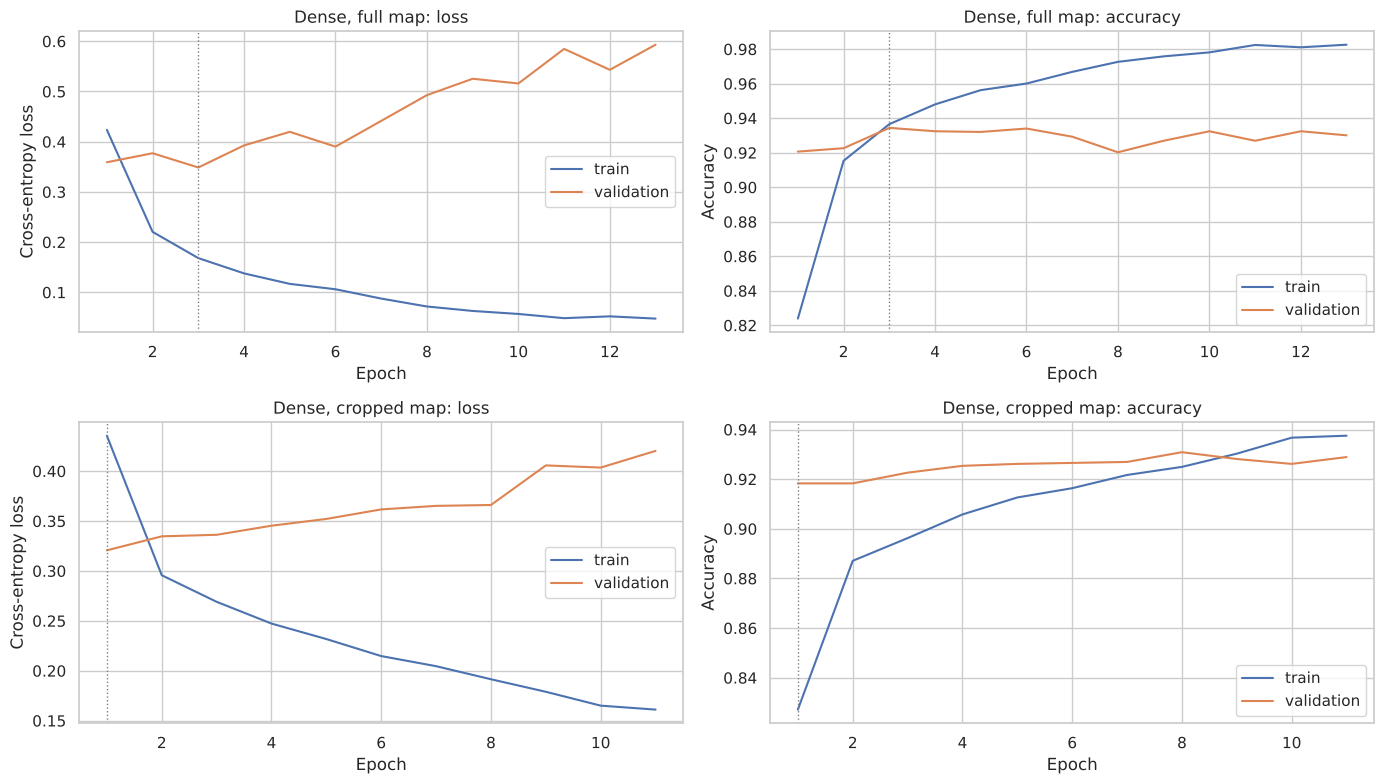

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, inp in enumerate(["full", "cropped"]):
    plot_history(histories[inp], f"Dense, {inp} map", axes[row, 0], axes[row, 1])
plt.tight_layout(); plt.savefig(FIG / "dl_09_dense_learning_curves.png", dpi=200); plt.show()

## 5. Summary of all models (test sessions)

In [7]:
cols = ["Val accuracy", "Test accuracy"] + [f"Test recall {c}" for c in CLASSES]
dense = (mlp_runs.groupby("Input")[cols].agg(["mean", "std"]))
for inp in ["full", "cropped"]:
    r = {"Model": "Dense (MLP)", "Input": f"{inp} map"}
    for c in cols:
        r[c] = dense.loc[inp, (c, "mean")]
    r["Test accuracy std (3 seeds)"] = dense.loc[inp, ("Test accuracy", "std")]
    r["Params"] = int(mlp_runs.loc[mlp_runs.Input == inp, "Params"].iloc[0])
    results.append(r)

summary = pd.DataFrame(results)[["Model", "Input"] + cols + ["Test accuracy std (3 seeds)", "Params"]]
summary.to_csv(RES / "dl_step3_results.csv", index=False)
summary.round(3)

,Model,Input,Val accuracy,Test accuracy,Test recall Cars,Test recall Drones,Test recall People,Test accuracy std (3 seeds),Params
0,Logistic regression,3 physical features,0.916,0.845,0.681,0.899,0.947,NaN,NaN
1,Random Forest,3 physical features,0.916,0.861,0.759,0.842,0.962,NaN,NaN
2,Random Forest,full map (raw values),0.917,0.912,0.849,0.960,0.930,NaN,NaN
3,Random Forest,cropped map (raw values),0.918,0.909,0.837,0.954,0.938,NaN,NaN
4,Dense (MLP),full map,0.927,0.886,0.824,0.911,0.920,0.009,205315.0
5,Dense (MLP),cropped map,0.921,0.887,0.798,0.908,0.948,0.008,70147.0


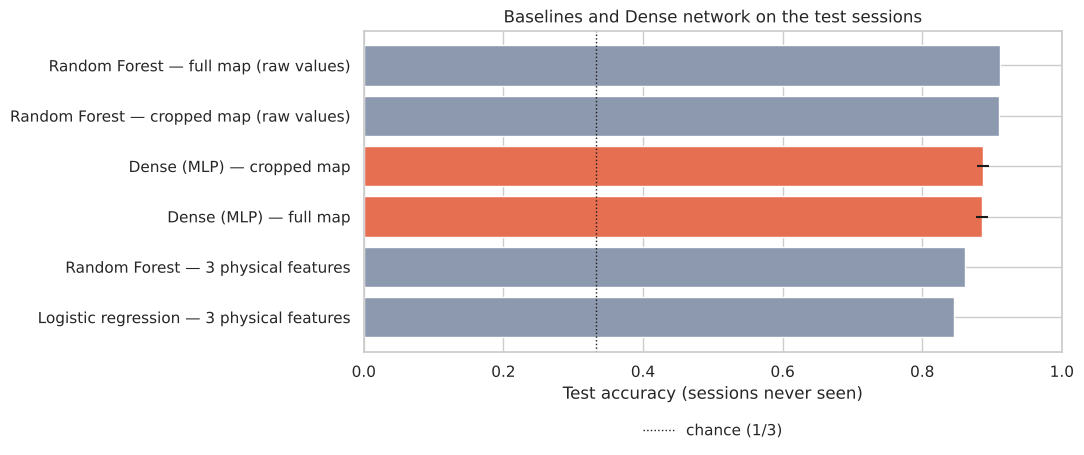

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.8))
lab = summary["Model"] + " — " + summary["Input"]
order = summary["Test accuracy"].sort_values().index
ax.barh(lab[order], summary.loc[order, "Test accuracy"],
        xerr=summary.loc[order, "Test accuracy std (3 seeds)"].fillna(0),
        color=["#e76f51" if "Dense" in m else "#8d99ae" for m in summary.loc[order, "Model"]])
ax.axvline(1 / 3, color="k", ls=":", lw=1, label="chance (1/3)")
ax.set(xlabel="Test accuracy (sessions never seen)", xlim=(0, 1), title="Baselines and Dense network on the test sessions")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout(); plt.savefig(FIG / "dl_10_step3_comparison.png", dpi=200); plt.show()

## 6. Confusion matrices (test sessions)

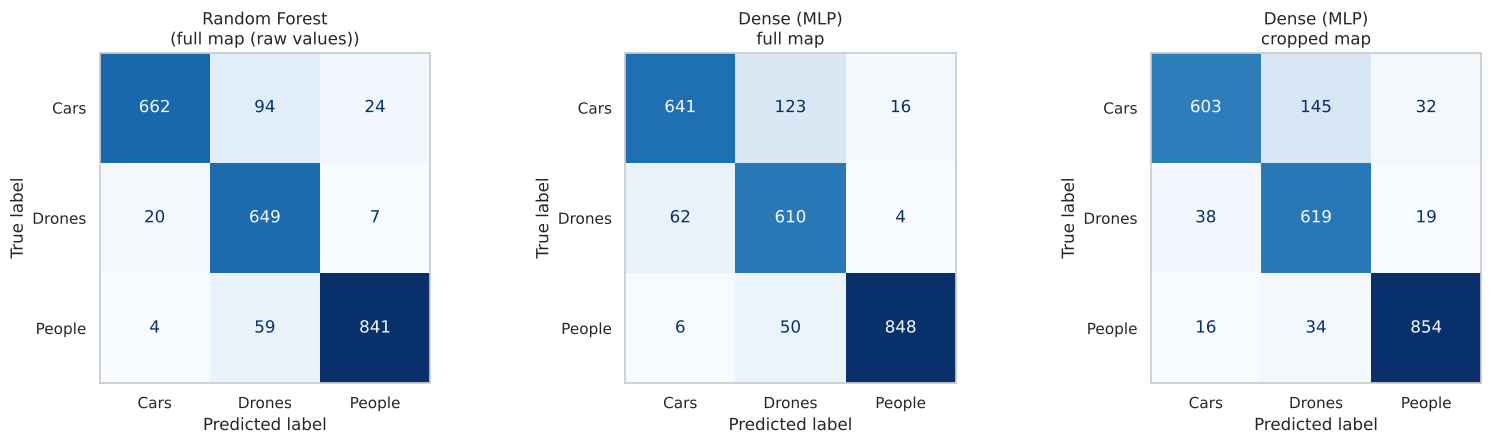

In [9]:
best_ml = summary[summary.Model != "Dense (MLP)"].sort_values("Test accuracy").iloc[-1]
show = [((best_ml.Model, best_ml.Input), f"{best_ml.Model}\n({best_ml.Input})"),
        (("Dense (MLP)", "full map"), "Dense (MLP)\nfull map"),
        (("Dense (MLP)", "cropped map"), "Dense (MLP)\ncropped map")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (key, title) in zip(axes, show):
    plot_confusion(y[te], preds[key], CLASSES, title, ax)
plt.tight_layout(); plt.savefig(FIG / "dl_11_step3_confusion.png", dpi=200); plt.show()

## 7. Conclusions
*(to be written in the report from the outputs above)*